In [1]:
# Startup

# Import different Python packages

import torch
from PIL import Image
from sam3.model_builder import build_sam3_image_model
from sam3.model.sam3_image_processor import Sam3Processor
from sam3.model.box_ops import box_xywh_to_cxcywh
from sam3.visualization_utils import draw_box_on_image,normalize_bbox,plot_results
import matplotlib.pyplot as plt
import numpy as np

# defining a custom function for printing an image with just the masks, no boxes or statistics, for visual clarity
def plot_results_masks_only(img, results):
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    nb_objects = len(results["scores"])
    print(f"found {nb_objects} object(s)")
    for i in range(nb_objects):
        color = COLORS[i % len(COLORS)]
        plot_mask(results["masks"][i].squeeze(0).cpu(), color=color)

/projectnb/urbanbiome/daily/.conda/envs/biom_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/projectnb/urbanbiome/daily/.conda/envs/biom_312/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [5]:
# Initialize the SAM3 segmentation model 
model = build_sam3_image_model()
# model = model.float() # ECD added to try to resolve float mismatch
# model = model.bfloat16() # ECD added this to try to resolve float mismatch
processor = Sam3Processor(model,confidence_threshold=0.25) # You can set confidence_threshold to be more or less relaxed.

In [3]:
# Load in an image

# removed this [:,:,0:3] because the image is in grayscale
# original code: img_1 = Image.fromarray(np.array(Image.open('../SEM Test Images/2025_URULE_T3_FEN_QU1_B2_3.tif'))) 

# ECD added to try to resolve grayscale error
# img_array = np.array(Image.open('../SEM Test Images/2025_URULE_T3_FEN_QU1_B2_3.tif')) # ECD added to try to resolve grayscale error
# img_array_rgb = np.stack([img_array]*3, axis=-1) # ECD added to try to resolve grayscale error
# img_1 = Image.fromarray(img_array_rgb) # ECD added to try to resolve grayscale error

img_array = np.array(Image.open('../SEM Test Images/Test Images/Stomata_Qrubra_2025_URULE_T3_COM_QU2_B1_2.tif'))
img_array_rgb = np.stack([img_array]*3, axis=-1).astype(np.float32)
img_1 = Image.fromarray(img_array_rgb.astype(np.uint8))

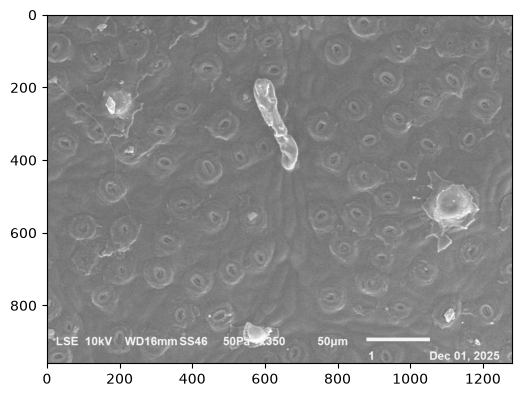

In [4]:
# Take a look at the loaded-in image
plt.figure(figsize=[6,6])
plt.imshow(img_1, cmap='gray')

In [14]:
# Prompt-based segmentation: describing the target object with words

    # original version
    # inference_state = processor.set_image(img_1) # "load in" the image
    # prompt = 'blob' # Set the Segmentation prompt
    # output = processor.set_text_prompt(state=inference_state,prompt=prompt) # perform segmentation

with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
    inference_state = processor.set_image(img_1)
    prompt = 'circle'
    output = processor.set_text_prompt(state=inference_state, prompt=prompt)

found 99 object(s)


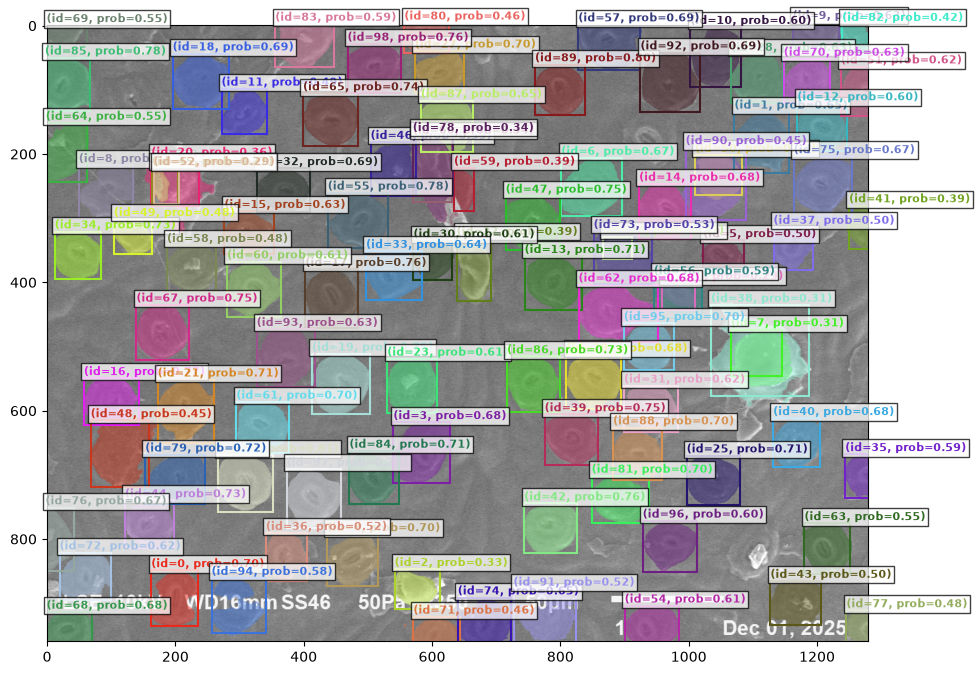

In [15]:
# Visualize results
plot_results(img_1,output)

In [8]:
# Get list of segmented stomata
masks, boxes, scores = output["masks"], output["boxes"], output["scores"]
print(len(masks)) # How many segmented stomata?

80


tensor(0.4219, device='cuda:0', dtype=torch.bfloat16)
tensor([187.0484, 870.6126, 211.2364, 911.7412], device='cuda:0')


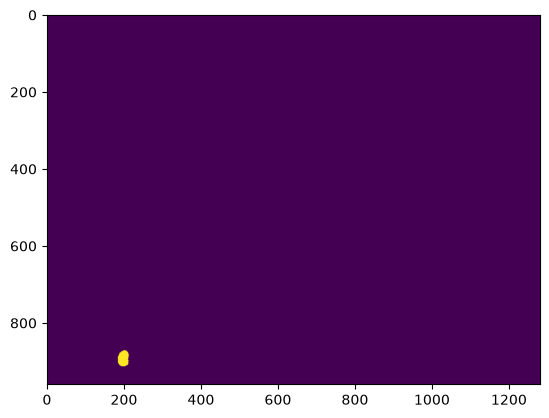

In [9]:
# Let's take a look at one of these segmented stomata
print(scores[0]) # Confidence score
print(boxes[0]) #Bounding box coordinates
plt.imshow(np.squeeze(masks[0].cpu().numpy())) #Visualize the segmentation

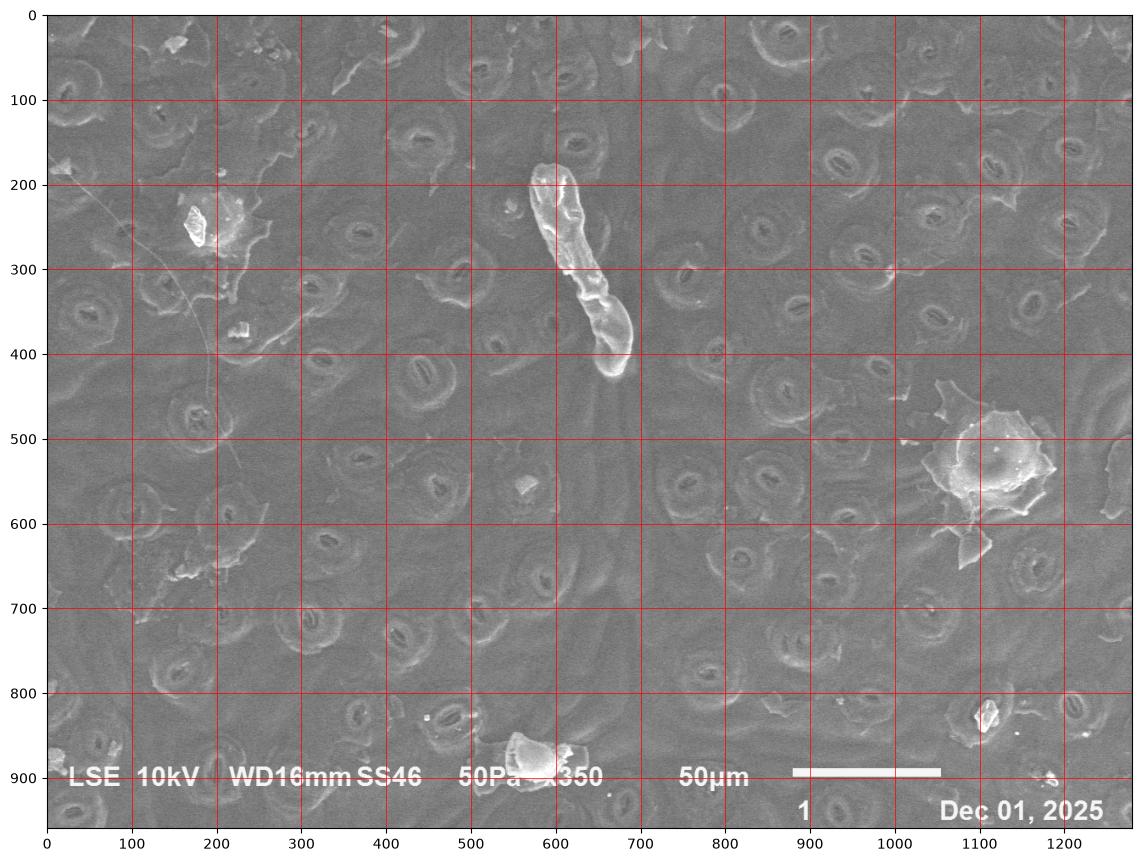

In [22]:
# Find coordinates of objects of interest
%matplotlib inline
plt.figure(figsize=[14,14])
plt.imshow(img_1, cmap='gray')
plt.axis('on')
plt.xticks(range(0, img_1.size[0], 100))
plt.yticks(range(0, img_1.size[1], 100))
plt.grid(True, color='red', linewidth=0.5)

In [21]:
# Example-based segmentation: visually identifying target object
width, height = img_1.size
# Set the boundaries of the example object. This is specified by [x,y,width,height]. So [300,350,100,100] means that the box starts at
# x=300, y=350, and the box is 100 pixels wide and 100 pixel tall
box_input_xywh = torch.tensor([800,200,100,100]).view(-1,4) # modify the coordinates on this line to show an example image
box_input_cxcywh = box_xywh_to_cxcywh(box_input_xywh)
norm_box_cxcywh = normalize_bbox(box_input_cxcywh, width, height).flatten().tolist()

found 88 object(s)


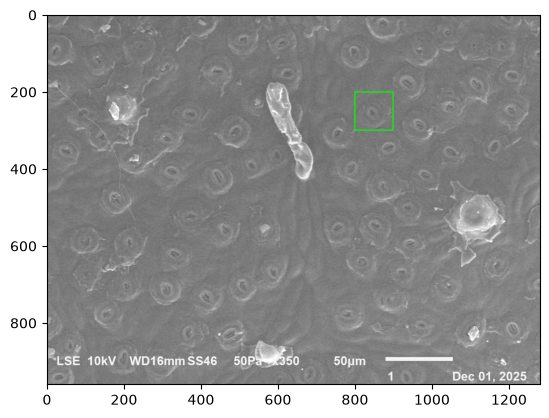

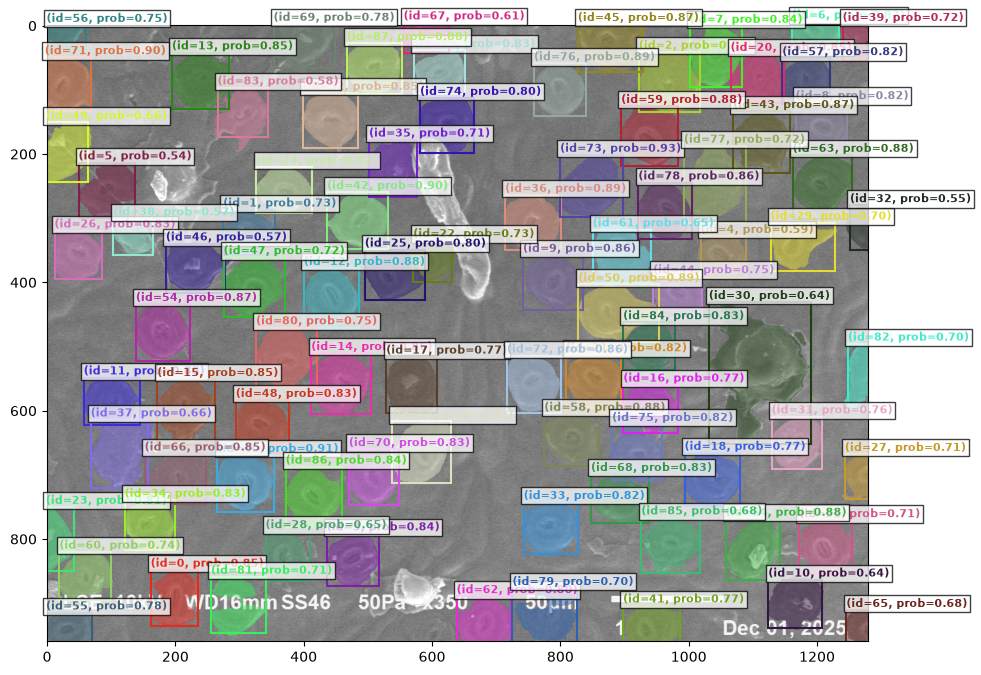

In [23]:
processor = Sam3Processor(model, confidence_threshold=0.5)
with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
    inference_state = processor.set_image(img_1)
    processor.reset_all_prompts(inference_state)
    inference_state = processor.add_geometric_prompt(
        state=inference_state, box=norm_box_cxcywh, label=True
    )

image_with_box = draw_box_on_image(img_1, box_input_xywh.flatten().tolist())
plt.imshow(image_with_box)
plot_results(img_1, inference_state)

In [24]:
masks, boxes, scores = inference_state["masks"], inference_state["boxes"], inference_state["scores"]

def plot_results(img, results):
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    nb_objects = len(results["scores"])
    print(f"found {nb_objects} object(s)")
    for i in range(nb_objects):
        color = COLORS[i % len(COLORS)]
        plot_mask(results["masks"][i].squeeze(0).cpu(), color=color)
        w, h = img.size
        prob = results["scores"][i].item()
        plot_bbox(
            h,
            w,
            results["boxes"][i].cpu(),
            text=f"(id={i}, {prob=:.2f})",
            box_format="XYXY",
            color=color,
            relative_coords=False,
        )

